
# XGBoost (Extreme Gradient Boosting)

XGBoost, which stands for Extreme Gradient Boosting, is an optimized and scalable implementation of the gradient boosting algorithm.

It is an ensemble learning technique that builds multiple decision trees sequentially, where each new tree attempts to correct the errors made by the previous trees.

XGBoost improves upon traditional Gradient Boosting through regularization, efficient computation, parallel processing during tree construction, and several optimization techniques.

Unlike traditional Gradient Boosting, XGBoost incorporates additional mechanisms to control model complexity and reduce overfitting.

## How XGBoost Works

1. The model begins with an initial prediction.
2. It calculates the errors made by the current model.
3. A new decision tree is constructed to improve the predictions.
4. The new tree's contribution is controlled by the learning rate.
5. Regularization helps control model complexity.
6. The process continues until the specified number of boosting rounds is reached or another stopping condition is met.

## Types of XGBoost Models

### 1.XGBoost Regressor

Used to predict continuous numerical values.

Examples:
- House price prediction
- Sales forecasting
- Stock price estimation
- Demand prediction

### 2. XGBoost Classifier

Used to predict categorical outcomes.

Examples:
- Fraud detection
- Customer churn prediction
- Disease classification
- Credit risk assessment

## Important XGBoost Parameters

- `n_estimators`: Number of boosting rounds.
- `learning_rate`: Controls the contribution of each tree.
- `max_depth`: Maximum depth of each tree.
- `subsample`: Fraction of training observations used for each tree.
- `colsample_bytree`: Fraction of features sampled for each tree.
- `reg_alpha`: L1 regularization.
- `reg_lambda`: L2 regularization.
- `min_child_weight`: Minimum sum of instance weights required in a child node.

## Advantages

- High predictive performance.
- Supports both regression and classification.
- Includes regularization to control overfitting.
- Handles nonlinear relationships and feature interactions.
- Supports missing-value handling.
- Offers feature importance measurements.

## Limitations

- Requires careful hyperparameter tuning.
- Can overfit if model complexity is not controlled.
- May require substantial computational resources for large datasets.
- Less interpretable than simple linear models.

## Applications

XGBoost is widely used in finance, healthcare, marketing, fraud detection, forecasting, and many other predictive modelling tasks.

In [23]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
import xgboost as xgb
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score,roc_curve)

In [24]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.


## Regression

In [25]:
# Load California Housing dataset
housing = fetch_california_housing()

# Convert features into DataFrame
housing_df = pd.DataFrame(housing.data,columns=housing.feature_names)

# Add target variable
housing_df['MedHouseVal'] = housing.target

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [26]:
# Column names
print("\nColumns:")
print(housing_df.columns.tolist())

# Dataset information
print("\nDataset Information:")
housing_df.info()

# Statistical summary
print("\nStatistical Summary:")
display(housing_df.describe())

# Missing values
print("\nMissing Values:")
print(housing_df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", housing_df.duplicated().sum())

# Target variable summary
print("\nTarget Variable Summary:")
print("Mean:", housing_df['MedHouseVal'].mean())
print("Median:", housing_df['MedHouseVal'].median())
print("Minimum:", housing_df['MedHouseVal'].min())
print("Maximum:", housing_df['MedHouseVal'].max())


Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows: 0

Target Variable Summary:
Mean: 2.0685581690891475
Median: 1.797
Minimum: 0.14999
Maximum: 5.00001


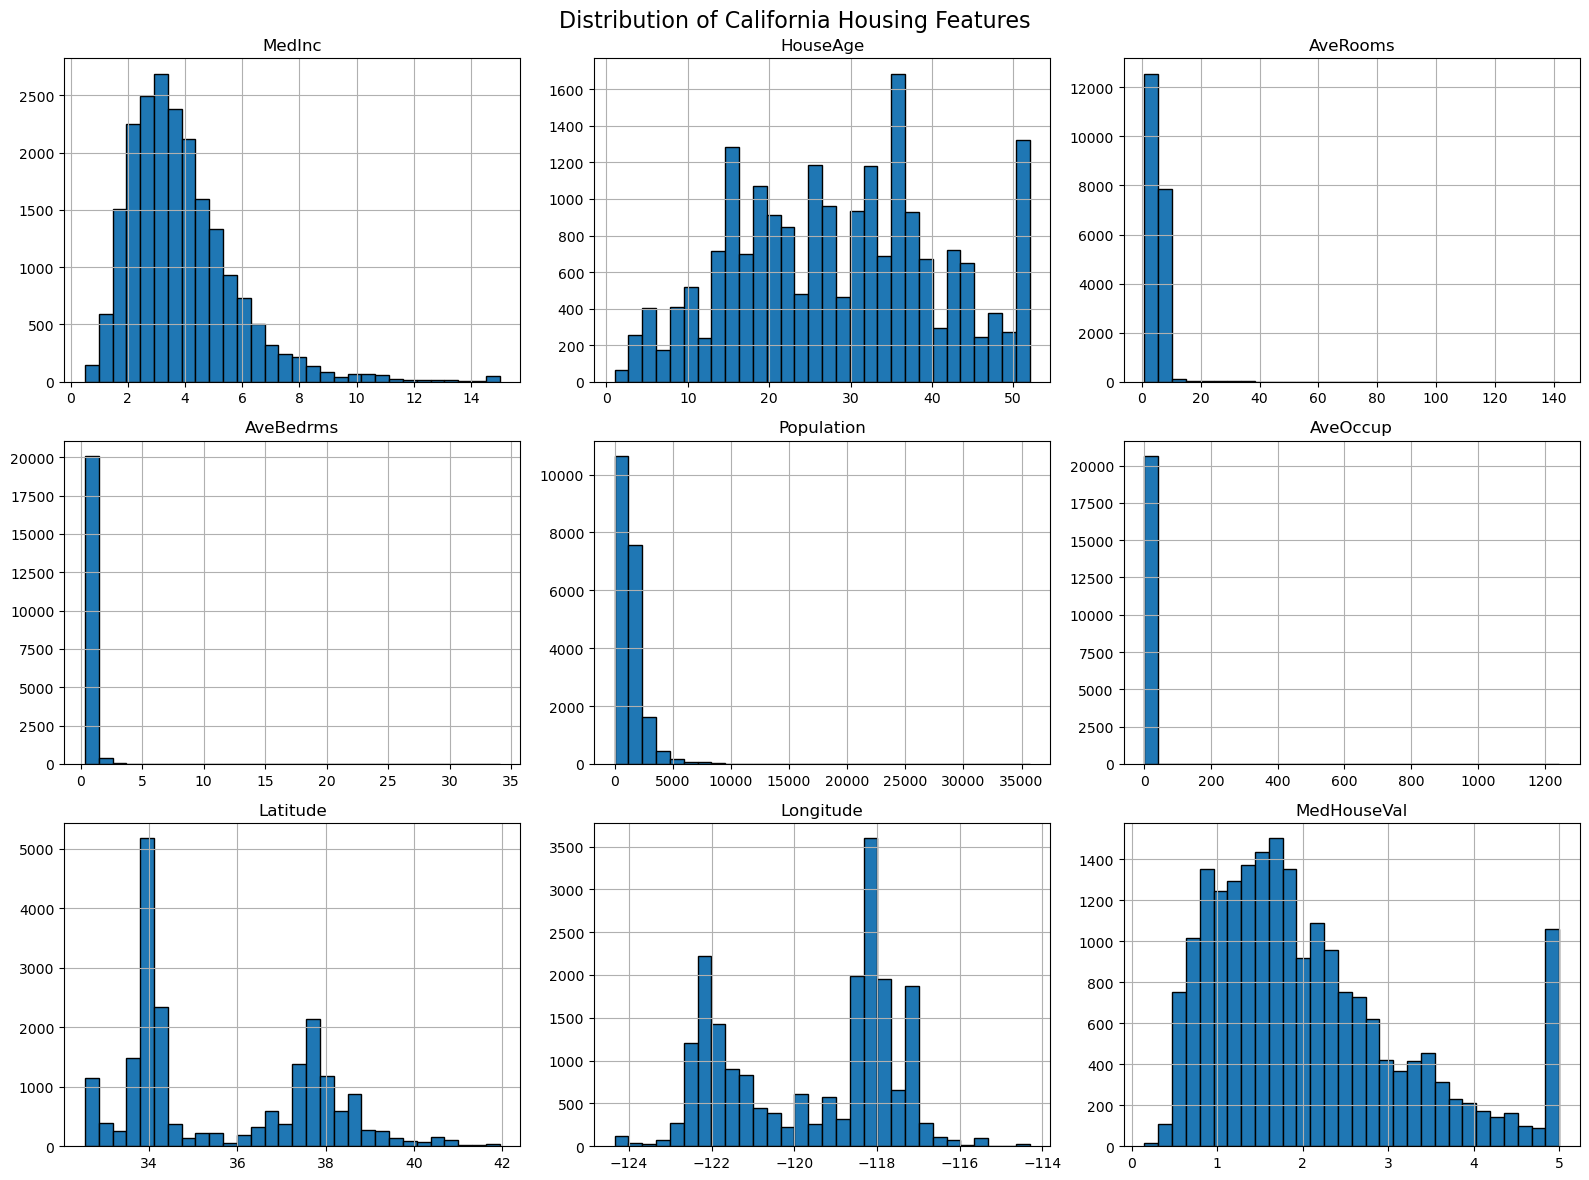

In [27]:
# numerical features distribution
# Plot feature distributions
housing_df.hist(figsize=(16, 12),bins=30,edgecolor='black')

plt.suptitle('Distribution of California Housing Features',fontsize=16)

plt.tight_layout()
plt.show()

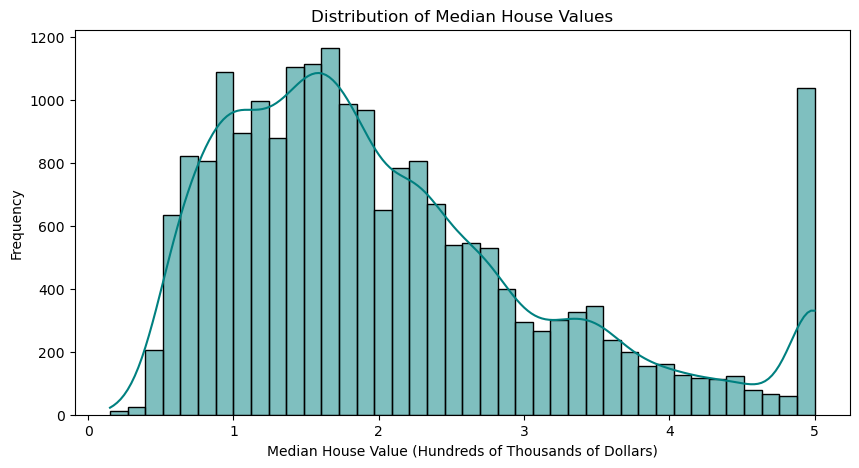

In [28]:
# Target variable distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=housing_df,x='MedHouseVal',bins=40,kde=True,color='teal')

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value (Hundreds of Thousands of Dollars)')
plt.ylabel('Frequency')

plt.show()

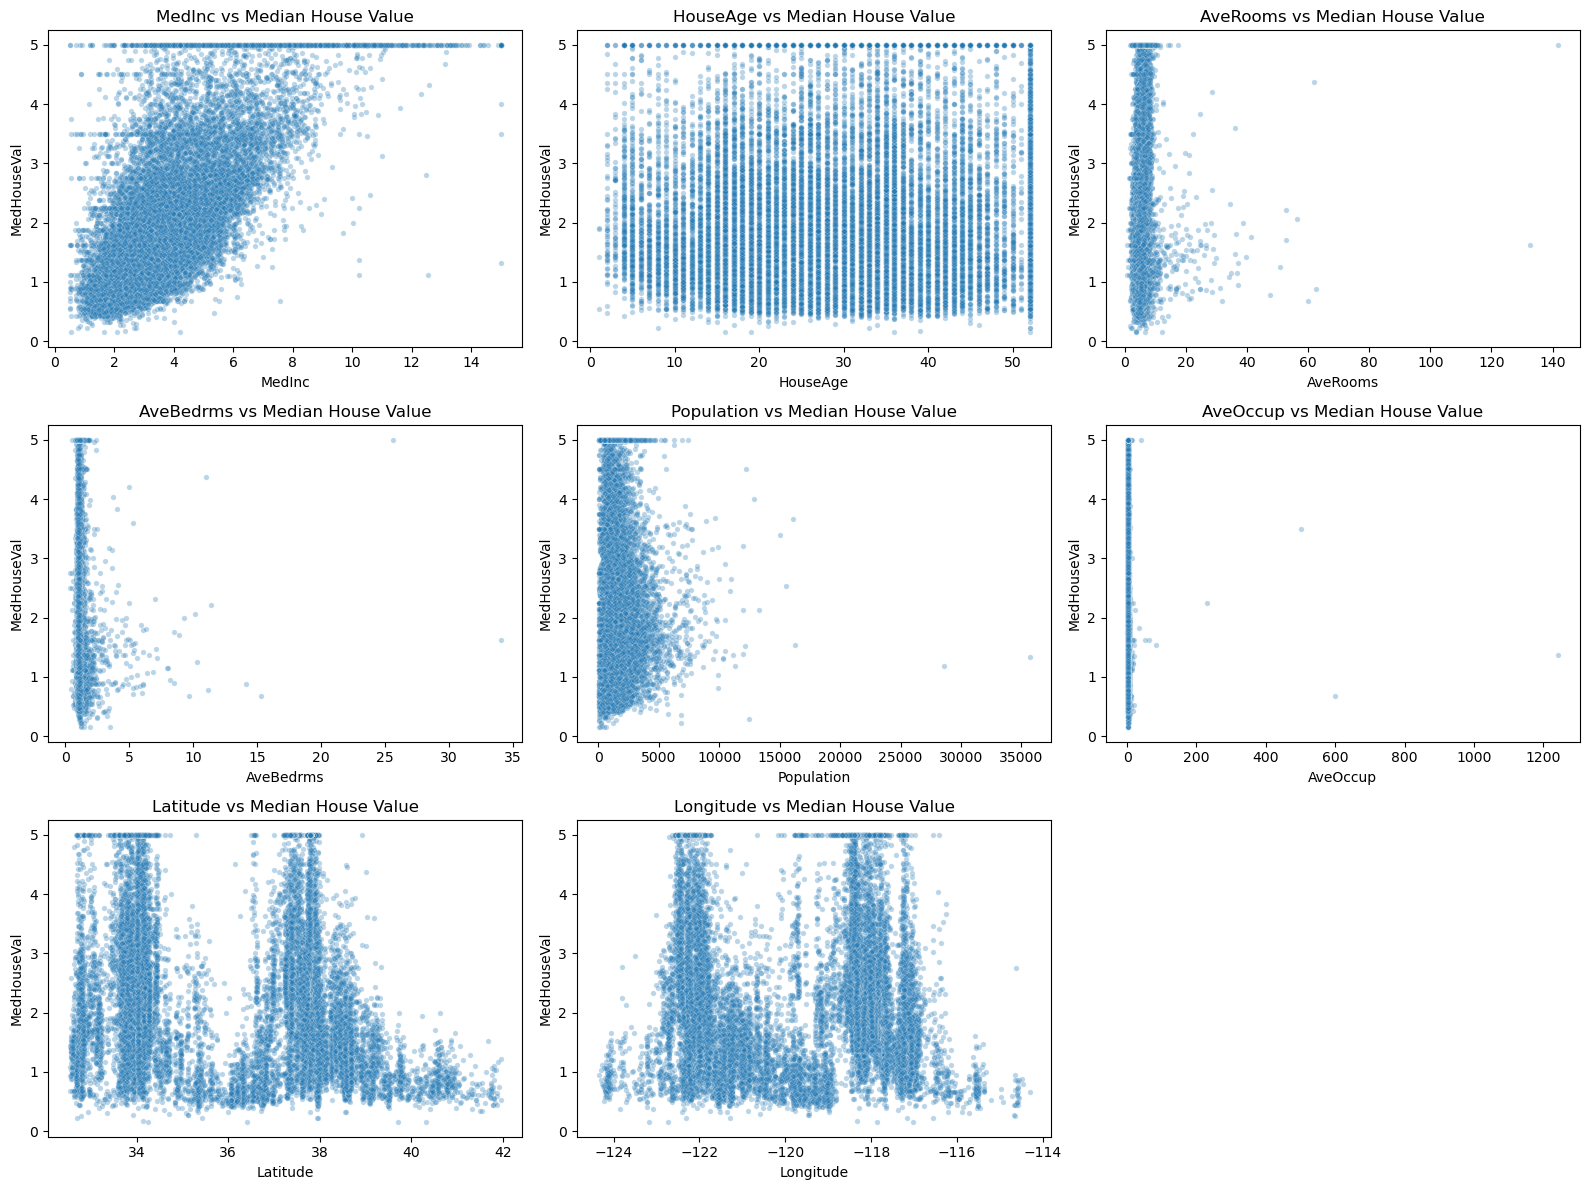

In [29]:
# feature rlship with target variable
features = [
    'MedInc',
    'HouseAge',
    'AveRooms',
    'AveBedrms',
    'Population',
    'AveOccup',
    'Latitude',
    'Longitude'
]

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)

    sns.scatterplot(data=housing_df,x=feature,y='MedHouseVal',alpha=0.3,s=15)

    plt.title(f'{feature} vs Median House Value')

plt.tight_layout()
plt.show()

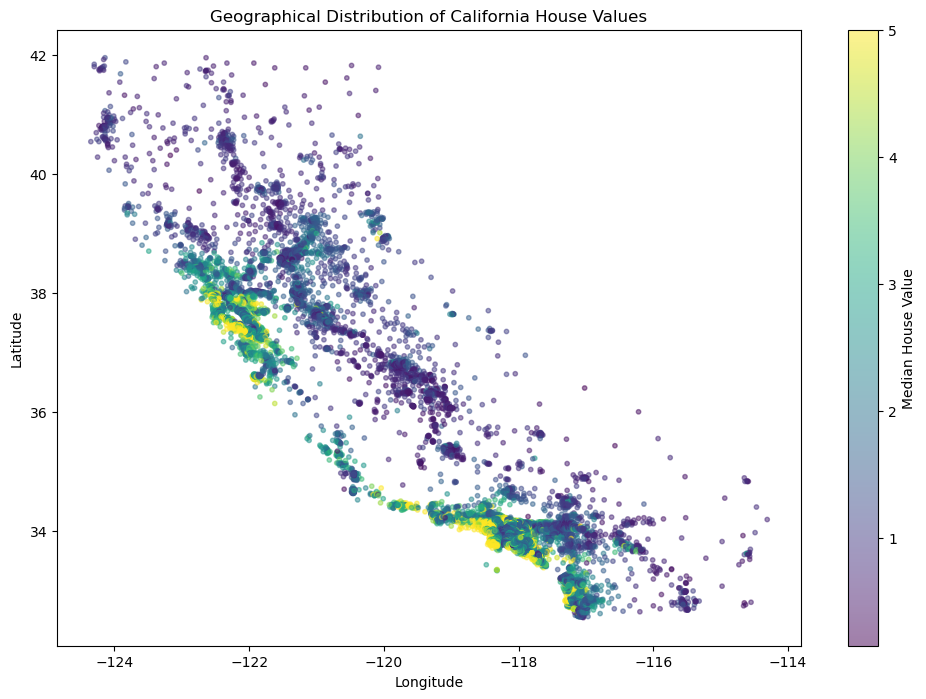

In [30]:
# Geographical distribution of house values
plt.figure(figsize=(12, 8))

scatter = plt.scatter(housing_df['Longitude'],housing_df['Latitude'],c=housing_df['MedHouseVal'],cmap='viridis',alpha=0.5,s=10)

plt.colorbar(scatter,label='Median House Value')

plt.title('Geographical Distribution of California House Values')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

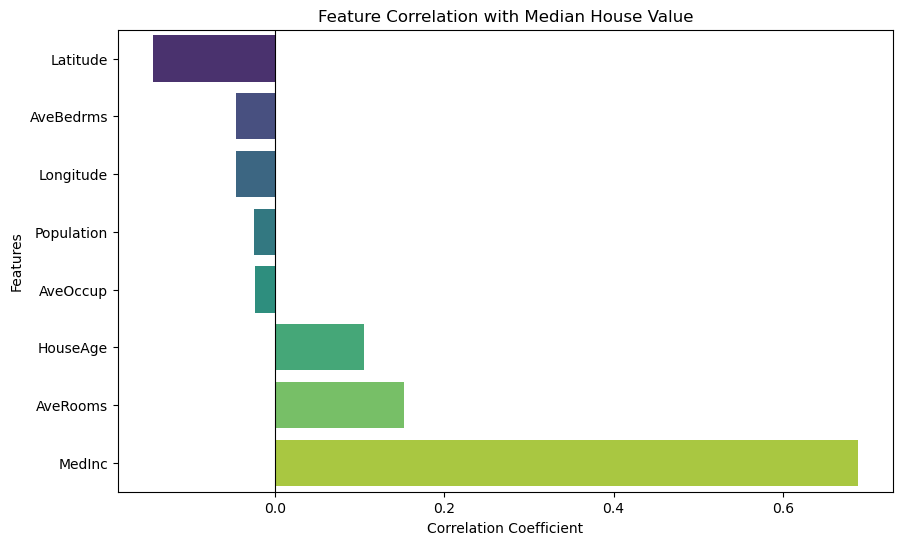

In [31]:
# feature correlation with target
# Calculate feature correlation with target
target_corr = housing_df.corr()['MedHouseVal'].drop('MedHouseVal')

target_corr = target_corr.sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(x=target_corr.values,y=target_corr.index,hue=target_corr.index,palette='viridis',legend=False)

plt.title('Feature Correlation with Median House Value')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')

plt.axvline(0, color='black', linewidth=0.8)

plt.show()

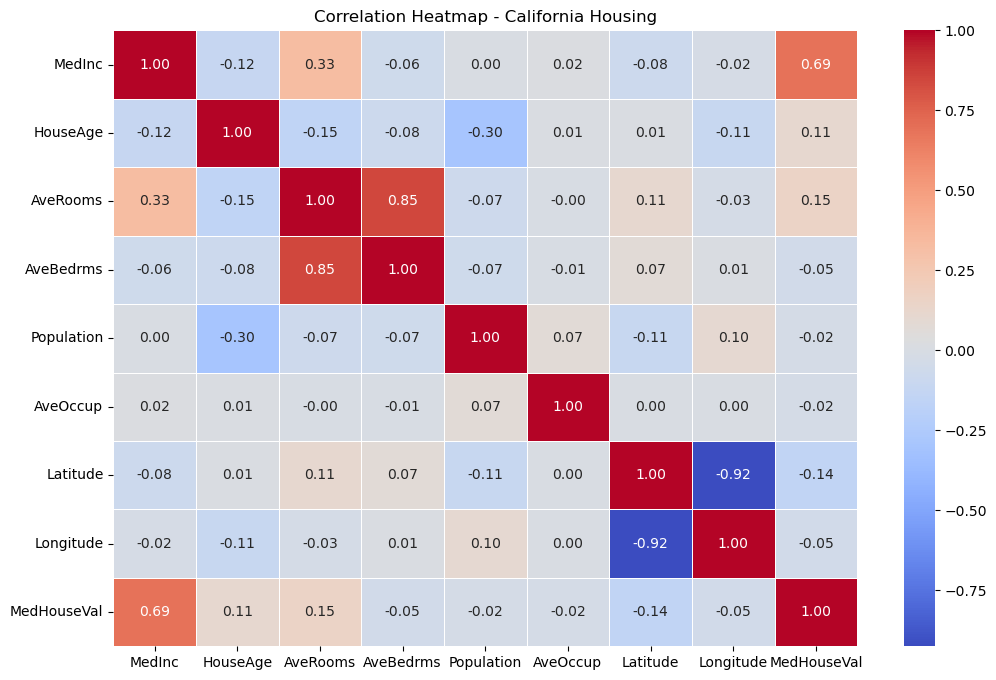

In [32]:
# correlation
# Calculate correlation matrix
correlation_matrix = housing_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)

plt.title('Correlation Heatmap - California Housing')
plt.show()

In [33]:
# Preprocessing

# Separate independent and dependent variables
X = housing_df.drop('MedHouseVal', axis=1)
y = housing_df['MedHouseVal']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [34]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [35]:
# Modelling
from xgboost import XGBRegressor

xgb_reg = XGBRegressor(n_estimators=100,learning_rate=0.1,max_depth=3,subsample=0.8,colsample_bytree=0.8,objective='reg:squarederror',random_state=42,n_jobs=-1)
# train 
xgb_reg.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [36]:
# Predictions
y_train_pred = xgb_reg.predict(X_train)
y_test_pred = xgb_reg.predict(X_test)

In [37]:
# Evaluation 
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print(f"MAE:  {mae:.6f}")
print(f"MSE:  {mse:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R2 Score: {r2:.6f}")

MAE:  0.368900
MSE:  0.291404
RMSE: 0.539818
R2 Score: 0.777624


In [38]:
# training vs testing performance
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Training R2 Score: {train_r2:.6f}")
print(f"Testing R2 Score:  {test_r2:.6f}")

Training R2 Score: 0.803690
Testing R2 Score:  0.777624


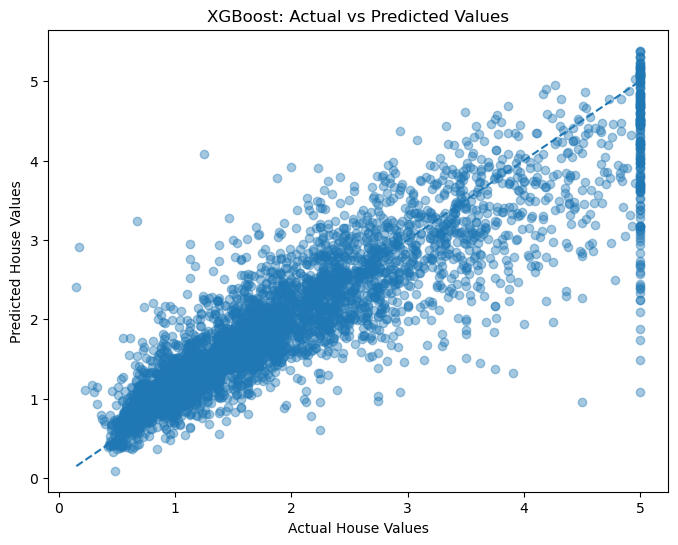

In [39]:
# Actual vs predicted

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.4)

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],linestyle='--')

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("XGBoost: Actual vs Predicted Values")
plt.show()

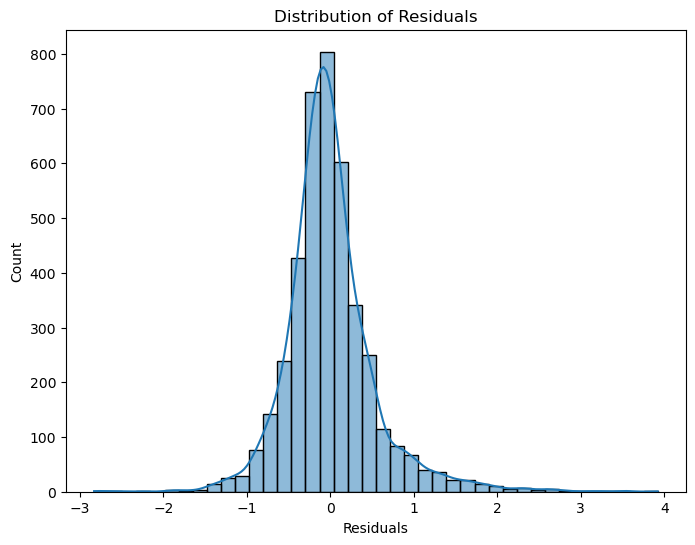

In [40]:
# Residual analysis
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
sns.histplot(residuals, bins=40, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.show()

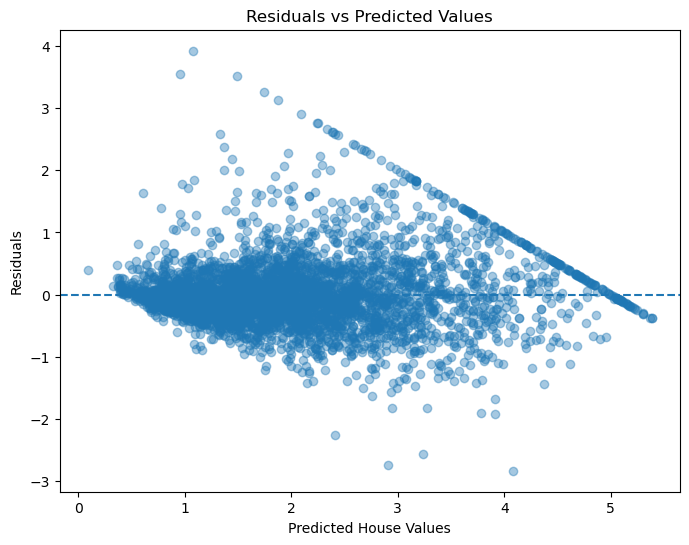

In [41]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test_pred, residuals, alpha=0.4)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

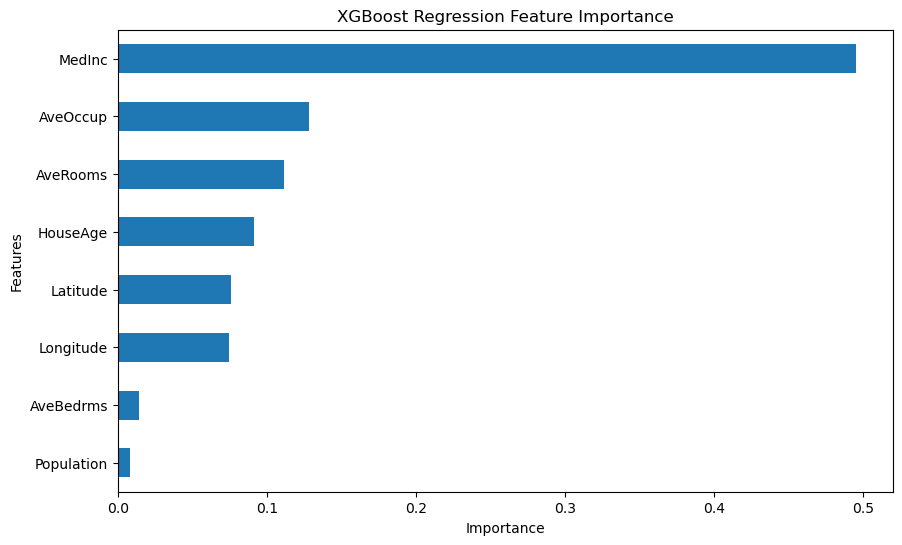

In [42]:
# feature importance

importance = pd.Series(xgb_reg.feature_importances_,index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importance.plot(kind='barh')

plt.title("XGBoost Regression Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [43]:
# Hyperparameter Tuning

param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}
# gridsearch cv

xgb_grid = GridSearchCV(estimator=XGBRegressor(objective='reg:squarederror',random_state=42,n_jobs=1),param_grid=param_grid,cv=3,scoring='neg_mean_squared_error',n_jobs=2,verbose=1)
# fit gridsearch

xgb_grid.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.8], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'n_estimators': [100, 200], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,2
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [44]:
print("Best Parameters:")
print(xgb_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(np.sqrt(-xgb_grid.best_score_))

Best Parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}

Best Cross-Validation RMSE:
0.4700060897971557


In [45]:
# evaluate tuned models

best_xgb_reg = xgb_grid.best_estimator_

y_tuned_pred = best_xgb_reg.predict(X_test)

tuned_mae = mean_absolute_error(y_test, y_tuned_pred)
tuned_mse = mean_squared_error(y_test, y_tuned_pred)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_tuned_pred)

print(f"MAE:  {tuned_mae:.6f}")
print(f"MSE:  {tuned_mse:.6f}")
print(f"RMSE: {tuned_rmse:.6f}")
print(f"R2 Score: {tuned_r2:.6f}")


MAE:  0.308478
MSE:  0.214056
RMSE: 0.462662
R2 Score: 0.836649


In [46]:
# compare original vs tuned
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Original XGBoost': [mae, mse, rmse, r2],
    'Tuned XGBoost': [
        tuned_mae, tuned_mse, tuned_rmse, tuned_r2
    ]
})

display(comparison)

,Metric,Original XGBoost,Tuned XGBoost
0,MAE,0.368900,0.308478
1,MSE,0.291404,0.214056
2,RMSE,0.539818,0.462662
3,R2 Score,0.777624,0.836649


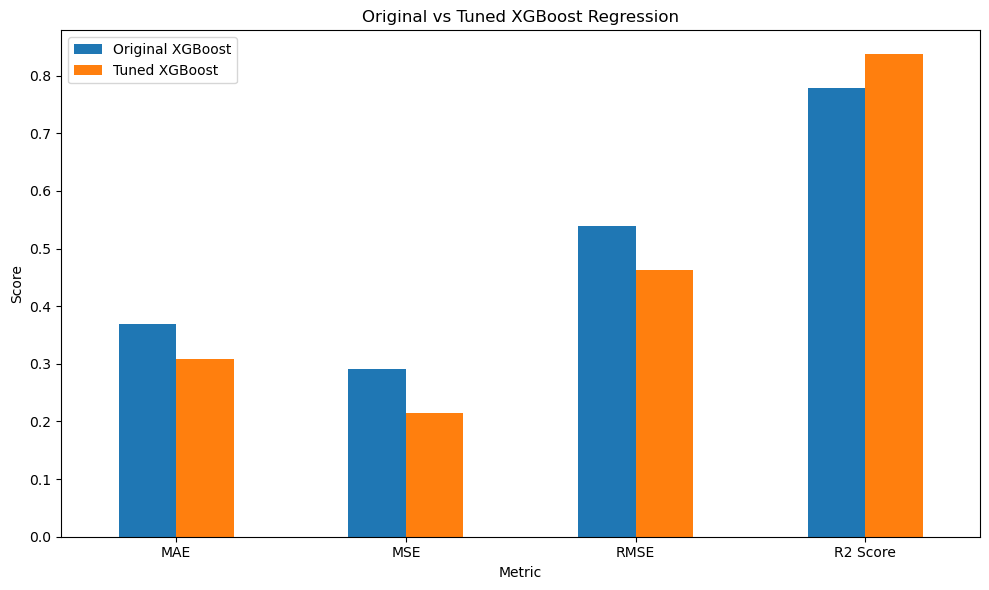

In [47]:

comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Original vs Tuned XGBoost Regression")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## Classification

### Wholesale customers

In [48]:
# load dataset
df = pd.read_csv('../Datasets/Wholesale customers data.csv')

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [49]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [50]:
# Preprocessing
X = df.drop('Channel', axis=1)
y = df['Channel'].map({1:1, 2:0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [51]:
# Modelling
params = {
    'objective':'binary:logistic',
    'max_depth':4,
    'learning_rate':0.1,
    'n_estimators':100,
    'alpha':10
}

model = XGBClassifier(**params)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [52]:
# Evaluation
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9090909090909091

Classification Report
              precision    recall  f1-score   support

           0       0.80      0.92      0.85        38
           1       0.97      0.90      0.93        94

    accuracy                           0.91       132
   macro avg       0.88      0.91      0.89       132
weighted avg       0.92      0.91      0.91       132



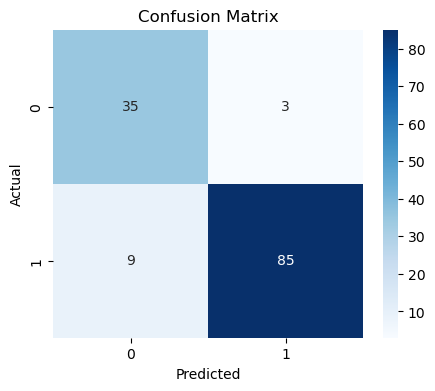

In [53]:
# confusion matrix
plt.figure(figsize=(5,4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

<Figure size 800x600 with 0 Axes>

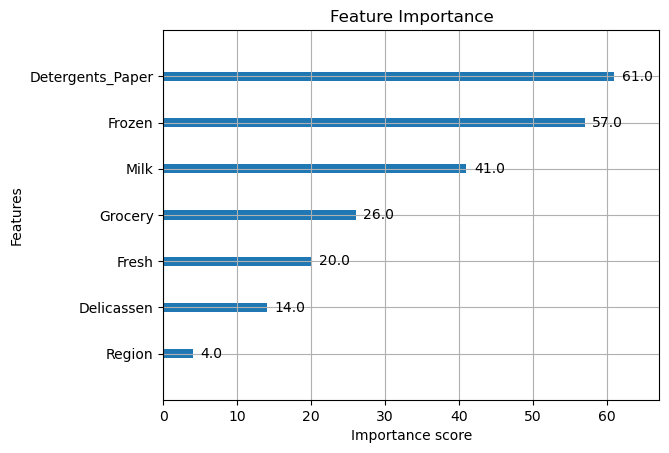

In [54]:
# feature importance
import xgboost as xgb
from xgboost import XGBClassifier
plt.figure(figsize=(8,6))
xgb.plot_importance(model)
plt.title("Feature Importance")
plt.show()

In [57]:
import os
import glob

paths = [
    r"C:\Program Files\Graphviz\bin\dot.exe",
    r"C:\Program Files (x86)\Graphviz\bin\dot.exe",
    r"C:\ProgramData\chocolatey\bin\dot.exe"
]

for path in paths:
    print(path, "FOUND" if os.path.exists(path) else "NOT FOUND")

C:\Program Files\Graphviz\bin\dot.exe NOT FOUND
C:\Program Files (x86)\Graphviz\bin\dot.exe NOT FOUND
C:\ProgramData\chocolatey\bin\dot.exe NOT FOUND


C:\Users\Public\Anaconda3\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

<Figure size 2000x1000 with 0 Axes>

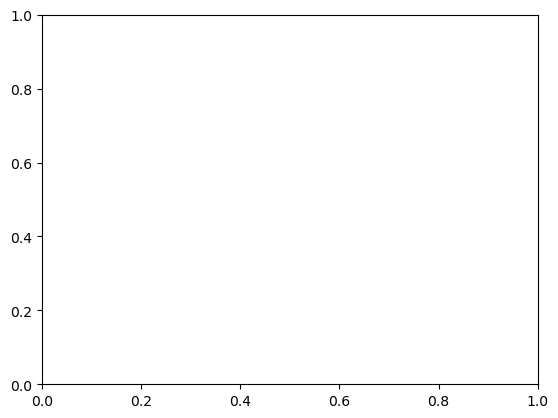

In [56]:
# xgboost decision tree
plt.figure(figsize=(20,10))
xgb.plot_tree(model, num_trees=0)
plt.show()

### Breast Cancer wisconsin dataset

In [58]:
# load dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [59]:
print("\nColumn Names:")
print(cancer_df.columns.tolist())

print("\nDataset Information:")
cancer_df.info()

print("\nStatistical Summary:")
display(cancer_df.describe())


Column Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [61]:
# target distribution
print(cancer_df['target'].value_counts())

print("\nTarget Labels:")
print(dict(enumerate(cancer.target_names)))

target
1    357
0    212
Name: count, dtype: int64

Target Labels:
{0: np.str_('malignant'), 1: np.str_('benign')}


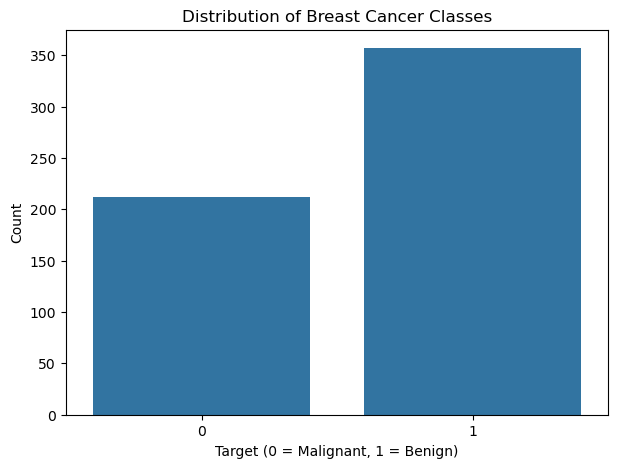

In [62]:
plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df,x='target')

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Target (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")
plt.show()

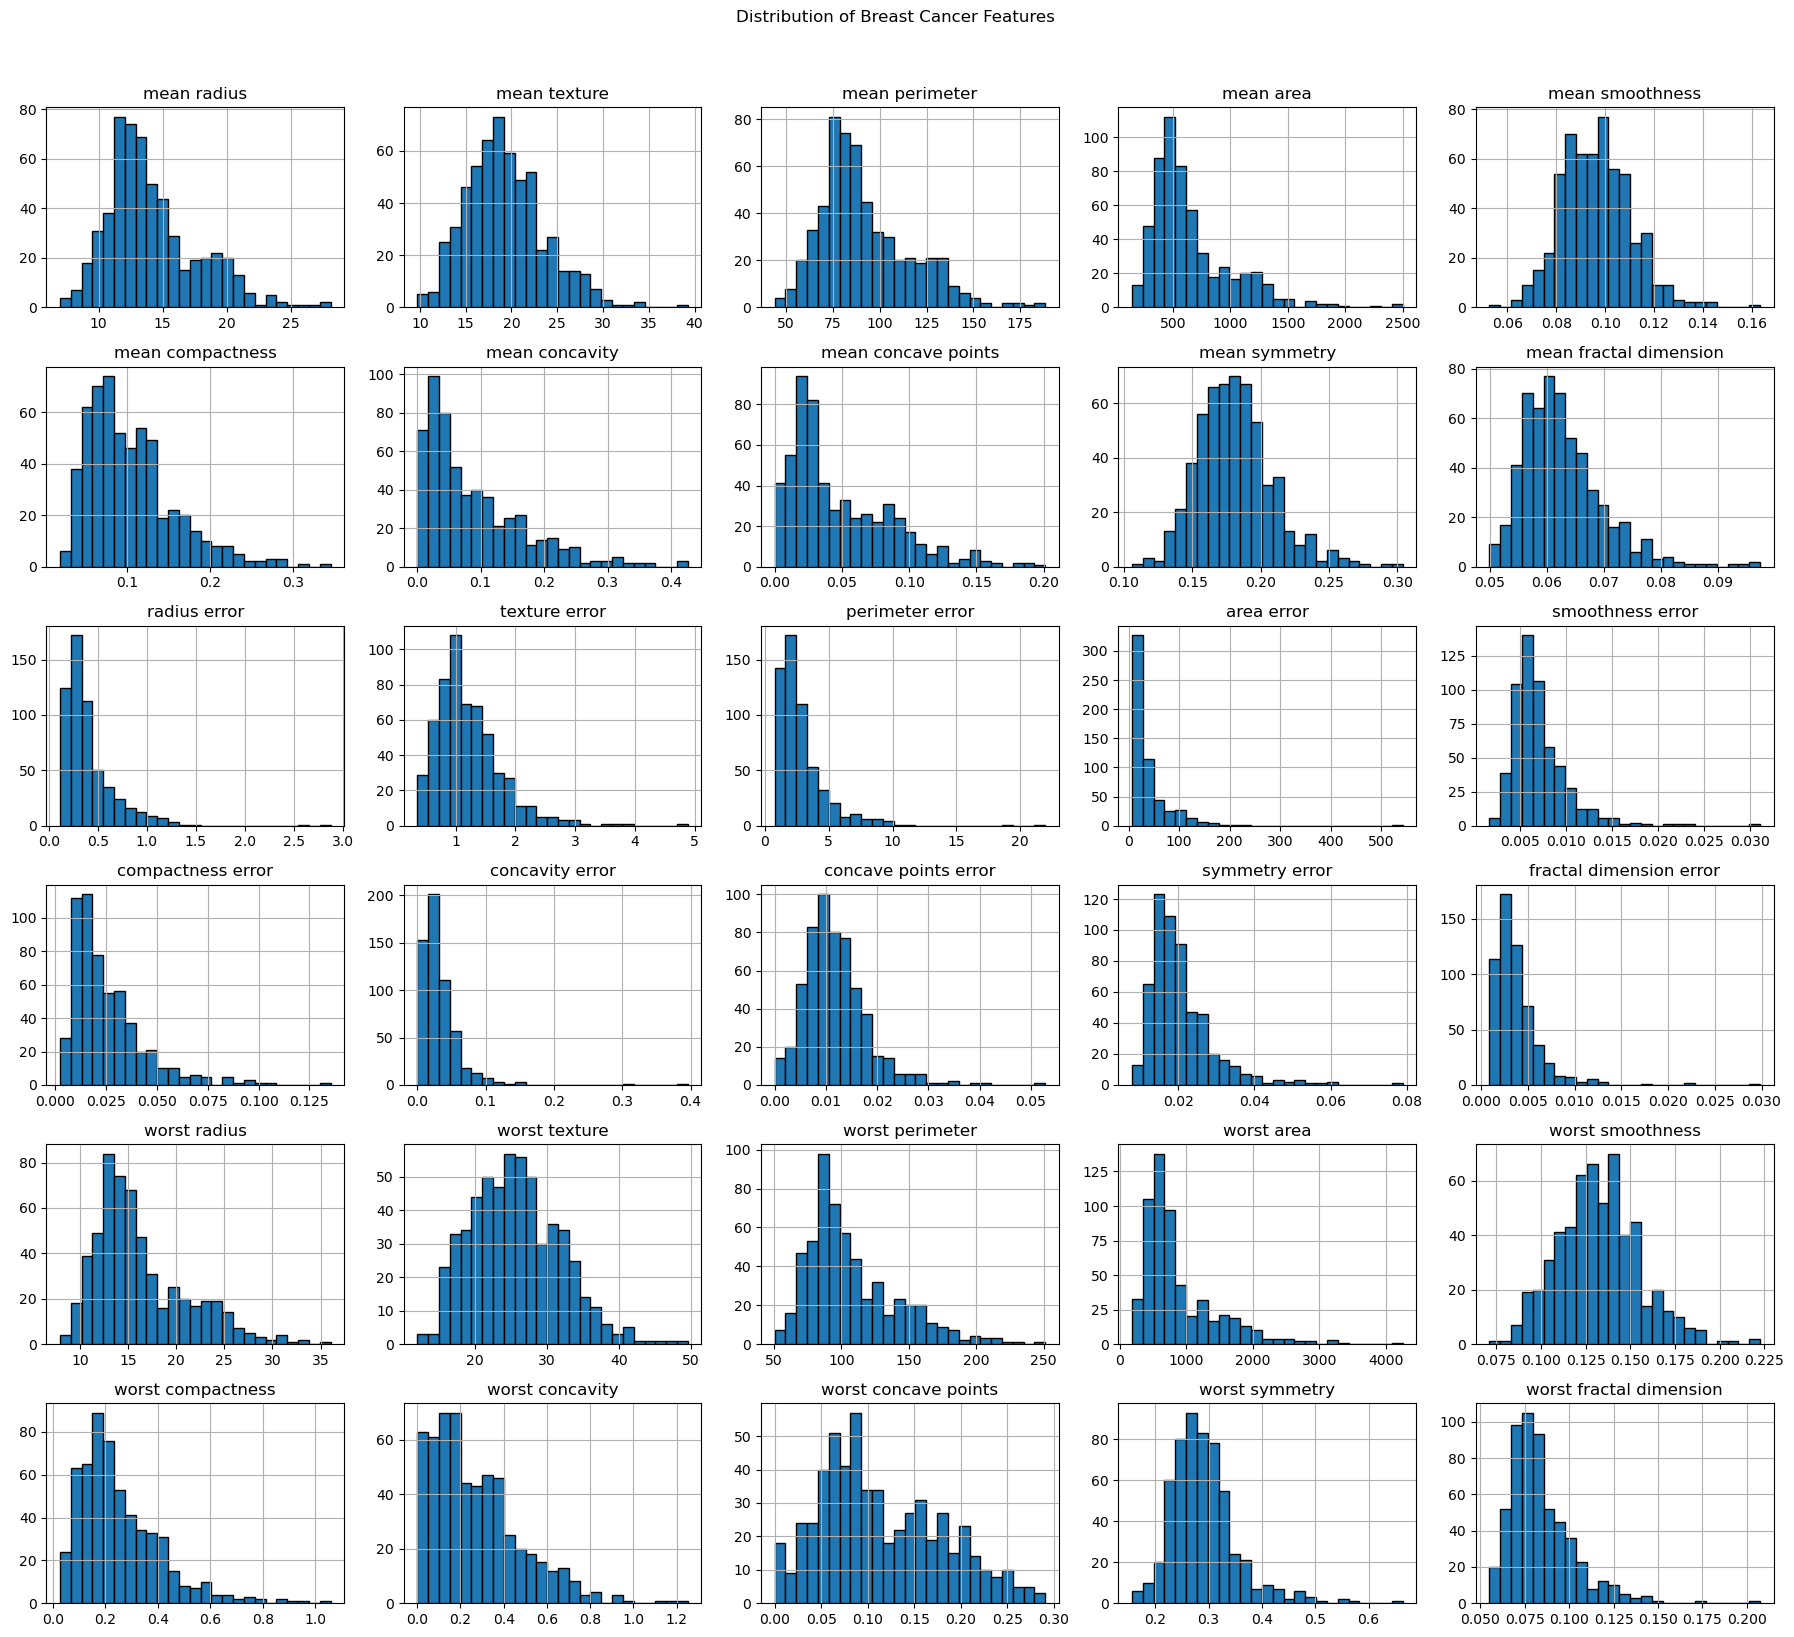

In [63]:
# numerical features distribution

cancer_df.drop(columns='target').hist(figsize=(18, 16),bins=25,edgecolor='black')

plt.suptitle("Distribution of Breast Cancer Features", y=1.02)
plt.tight_layout()
plt.show()

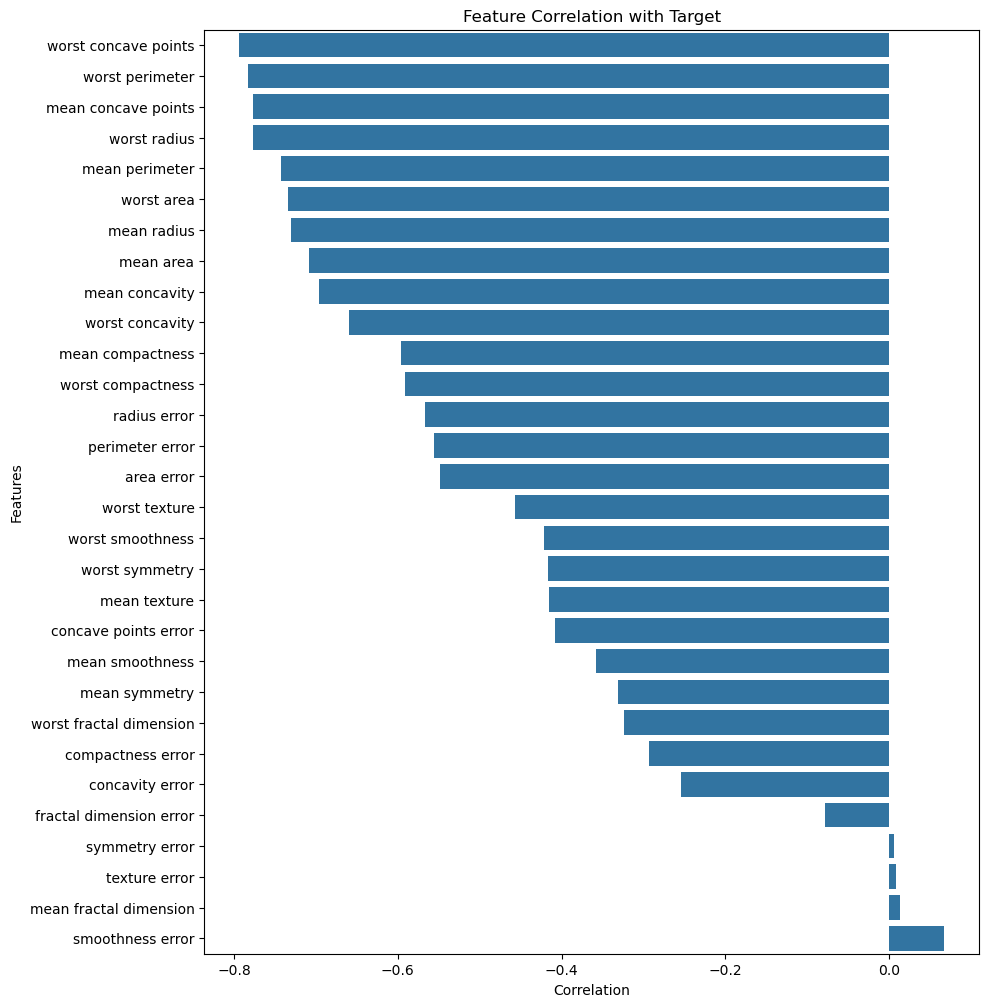

In [65]:
# feature rlship with target

target_corr = (cancer_df.corr()['target'].drop('target').sort_values())

plt.figure(figsize=(10, 12))

sns.barplot(x=target_corr.values,y=target_corr.index)

plt.title("Feature Correlation with Target")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.show()

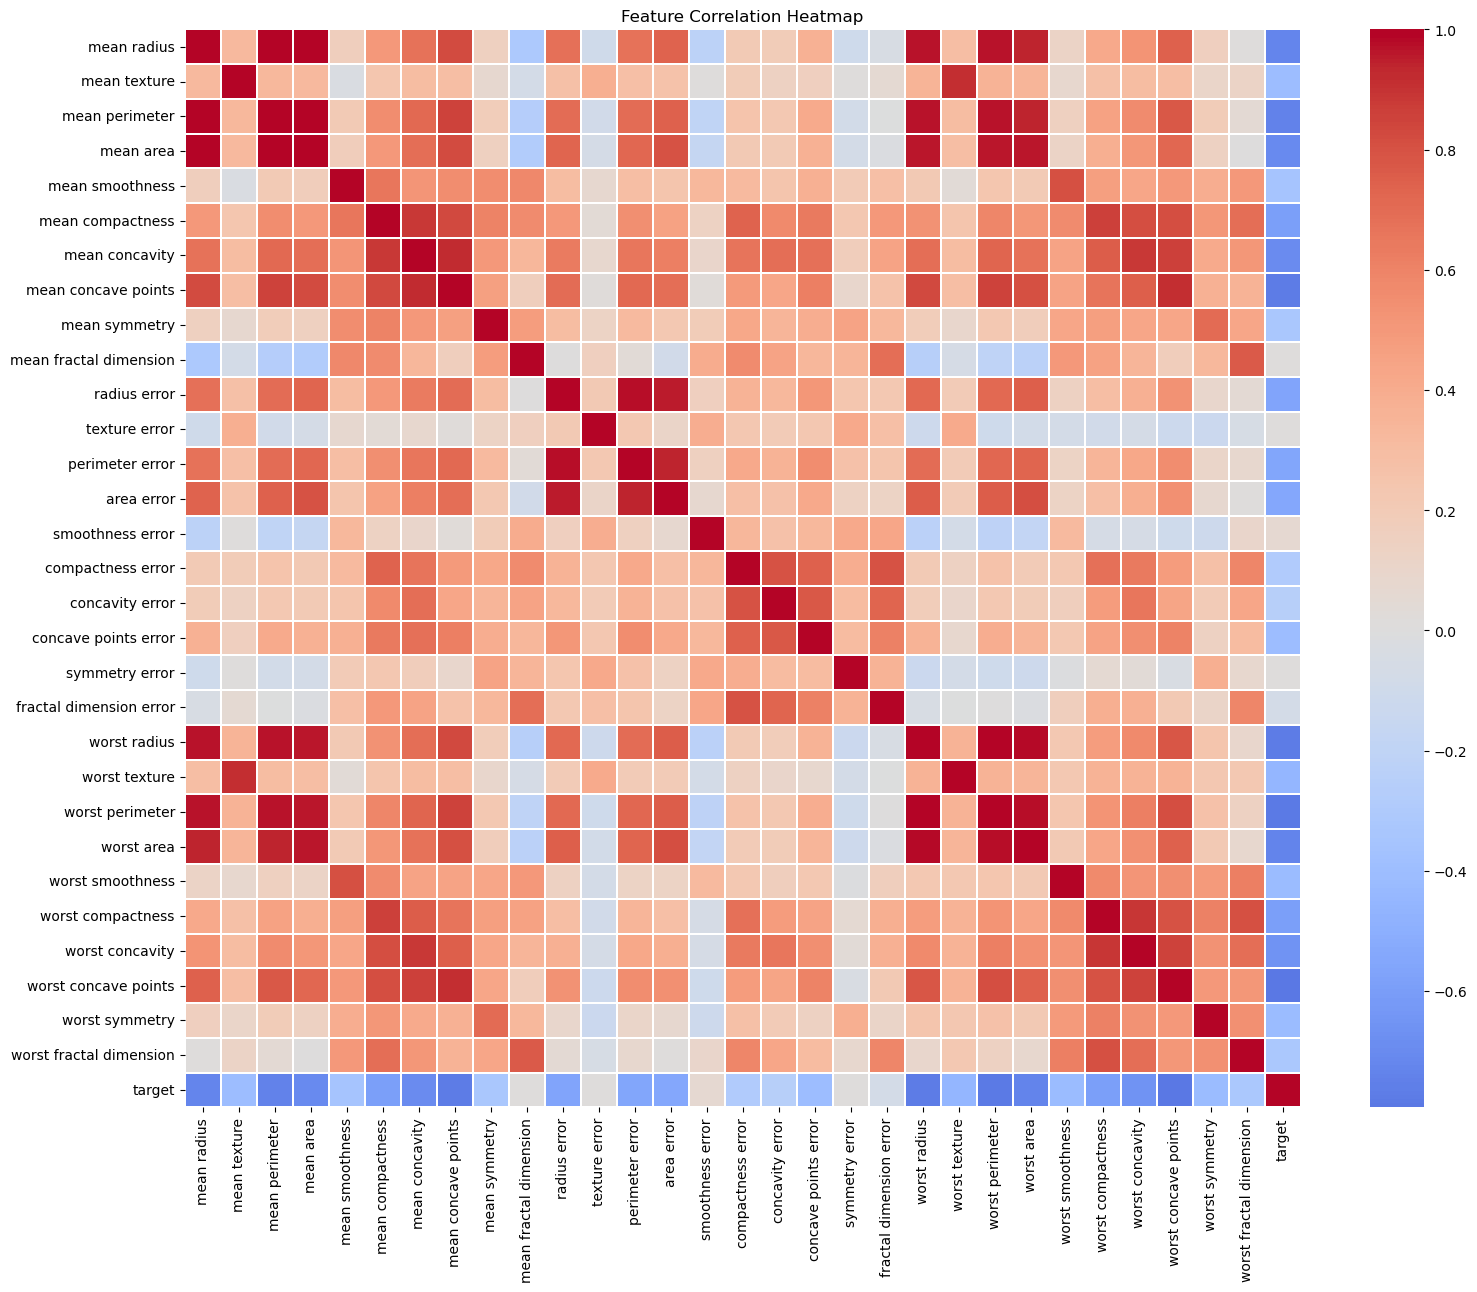

In [64]:
# correlation

plt.figure(figsize=(18, 14))

correlation = cancer_df.corr()

sns.heatmap(correlation,cmap='coolwarm',center=0,linewidths=0.3)

plt.title("Feature Correlation Heatmap")
plt.show()

In [66]:
# Preprocessing
# Independent variables
X = cancer_df.drop('target', axis=1)

# Dependent variable
y = cancer_df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [67]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)


In [68]:

print("Training class distribution:")
display(y_train.value_counts())

print("\nTesting class distribution:")
display(y_test.value_counts())

Training class distribution:


target
1    285
0    170
Name: count, dtype: int64


Testing class distribution:


target
1    72
0    42
Name: count, dtype: int64

In [69]:
# Modelling
xgb_clf = XGBClassifier(n_estimators=100,learning_rate=0.1,max_depth=3,subsample=0.8,colsample_bytree=0.8,objective='binary:logistic',eval_metric='logloss',random_state=42,n_jobs=-1)

xgb_clf.fit(X_train, y_train)# train 

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [70]:
# prediction

y_train_pred = xgb_clf.predict(X_train)
y_test_pred = xgb_clf.predict(X_test)

# Predicted probabilities
y_test_proba = xgb_clf.predict_proba(X_test)[:, 1]

In [71]:
# Evaluation
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"Accuracy:  {accuracy:.6f}")
print(f"Precision: {precision:.6f}")
print(f"Recall:    {recall:.6f}")
print(f"F1 Score:  {f1:.6f}")
print(f"ROC-AUC:   {roc_auc:.6f}")

Accuracy:  0.964912
Precision: 0.959459
Recall:    0.986111
F1 Score:  0.972603
ROC-AUC:   0.994048


In [75]:
# training vs testing performance

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.6f}")
print(f"Testing Accuracy:  {test_accuracy:.6f}")

Training Accuracy: 1.000000
Testing Accuracy:  0.964912


In [72]:
# classification report

print(classification_report(y_test,y_test_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



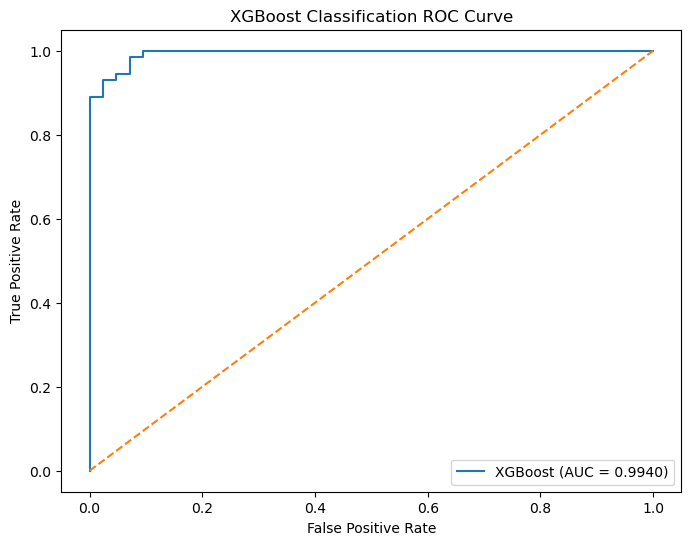

In [74]:
# ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f'XGBoost (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost Classification ROC Curve")
plt.legend()
plt.show()

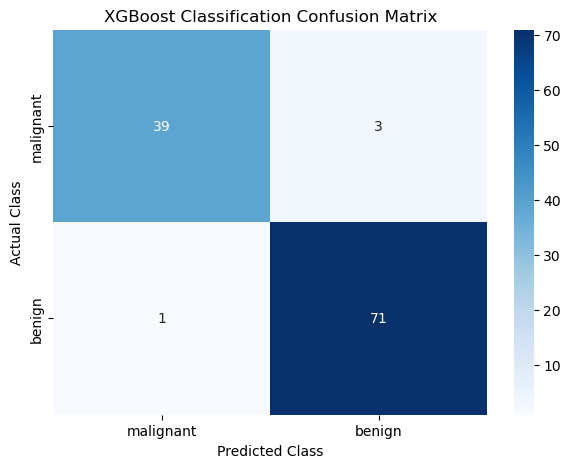

In [73]:
# confusion matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=cancer.target_names,yticklabels=cancer.target_names)

plt.title("XGBoost Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

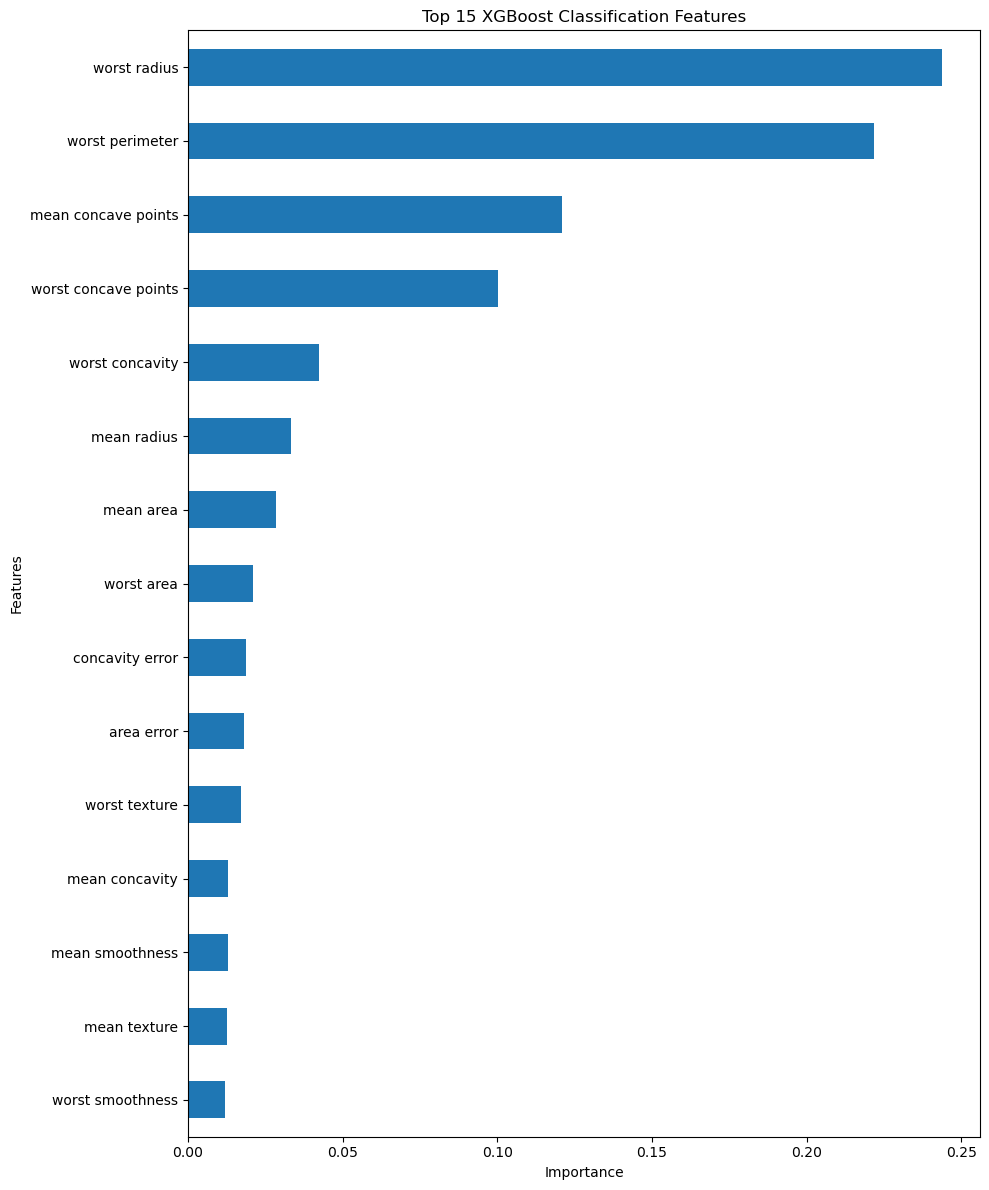

In [76]:
# feature importance
importance = pd.Series(xgb_clf.feature_importances_,index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 12))

importance.tail(15).plot(kind='barh')

plt.title("Top 15 XGBoost Classification Features")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [77]:

malignant_recall = recall_score(y_test,y_test_pred,pos_label=0)

malignant_precision = precision_score(y_test,y_test_pred,pos_label=0)

print(f"Malignant Precision: {malignant_precision:.6f}")
print(f"Malignant Recall:    {malignant_recall:.6f}")

Malignant Precision: 0.975000
Malignant Recall:    0.928571


In [79]:
# Hyperparameter tuning
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}
# gridsearch cv
xgb_grid = GridSearchCV(
    estimator=XGBClassifier(objective='binary:logistic',eval_metric='logloss',random_state=42,n_jobs=1),
    param_grid=param_grid,cv=3,scoring='f1',n_jobs=2,verbose=1)

xgb_grid.fit(X_train, y_train) # fit gridsearch

Fitting 3 folds for each of 32 candidates, totalling 96 fits


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'n_estimators': [100, 200], ...}"
,scoring,'f1'
,n_jobs,2
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [80]:
print("Best Parameters:")
print(xgb_grid.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(xgb_grid.best_score_)

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}

Best Cross-Validation F1 Score:
0.9721818564012575


In [81]:
# predictions
best_xgb_clf = xgb_grid.best_estimator_

y_tuned_pred = best_xgb_clf.predict(X_test)

y_tuned_proba = best_xgb_clf.predict_proba(X_test)[:, 1]

In [82]:
# evaluation tuned model
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)

tuned_precision = precision_score(y_test, y_tuned_pred)
tuned_recall = recall_score(y_test, y_tuned_pred)
tuned_f1 = f1_score(y_test, y_tuned_pred)

tuned_roc_auc = roc_auc_score(y_test, y_tuned_proba)

print(f"Accuracy:  {tuned_accuracy:.6f}")
print(f"Precision: {tuned_precision:.6f}")
print(f"Recall:    {tuned_recall:.6f}")
print(f"F1 Score:  {tuned_f1:.6f}")
print(f"ROC-AUC:   {tuned_roc_auc:.6f}")

Accuracy:  0.956140
Precision: 0.946667
Recall:    0.986111
F1 Score:  0.965986
ROC-AUC:   0.993056


In [83]:
print(classification_report(y_test,y_tuned_pred,target_names=cancer.target_names))


              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [84]:

print("Malignant Precision:",
      precision_score(y_test, y_tuned_pred, pos_label=0))

print("Malignant Recall:",
      recall_score(y_test, y_tuned_pred, pos_label=0))

Malignant Precision: 0.9743589743589743
Malignant Recall: 0.9047619047619048


In [85]:

comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Original XGBoost': [
        accuracy, precision, recall, f1, roc_auc
    ],
    'Tuned XGBoost': [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ]
})

display(comparison)

,Metric,Original XGBoost,Tuned XGBoost
0,Accuracy,0.964912,0.956140
1,Precision,0.959459,0.946667
2,Recall,0.986111,0.986111
3,F1 Score,0.972603,0.965986
4,ROC-AUC,0.994048,0.993056


## Conclusion

The XGBoost classifier achieved strong classification performance on the Breast Cancer Wisconsin dataset.

The original model achieved an accuracy of approximately 96.49%, an F1 score of 97.26%, and a ROC-AUC of 99.40%.

Hyperparameter tuning did not improve the model's overall test performance. The original model performed better across most evaluation metrics and demonstrated better malignant recall.

Therefore, the original XGBoost classifier was selected as the final model.

**Note:** This experiment is for educational purposes and does not establish clinical suitability. The model should not be used independently for medical diagnosis.
